In [2]:
print("AMD Digital Twin Project Setup Successful!")

AMD Digital Twin Project Setup Successful!


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
import os

DATA_PATH = "../data/raw"

print("Contents of raw data folder:")
print(os.listdir(DATA_PATH))

Contents of raw data folder:
['OCTDL']


In [5]:
import os

print("Current working directory:")
print(os.getcwd())

Current working directory:
c:\Users\vibhu\OneDrive\图片\文档\AMD-Digital-Twin\notebooks


In [6]:
for root, dirs, files in os.walk("../data/raw"):
    level = root.replace("../data/raw", "").count(os.sep)
    indent = " " * 4 * level
    print(f"{indent}{os.path.basename(root)}/")

    subindent = " " * 4 * (level + 1)

    for file in files[:5]:
        print(f"{subindent}{file}")

    if len(files) > 5:
        print(f"{subindent}... ({len(files)} files)")

raw/
    OCTDL/
        OCTDL_labels.csv
        AMD/
            amd_1047099_1.jpg
            amd_1047099_2.jpg
            amd_1047099_3.jpg
            amd_1047099_4.jpg
            amd_1084498_1.jpg
            ... (1231 files)
        DME/
            dme_1057060_1.jpg
            dme_1072780_1.jpg
            dme_1132061_1.jpg
            dme_1132061_2.jpg
            dme_1188282_1.jpg
            ... (147 files)
        ERM/
            erm_1043186_1.jpg
            erm_1043186_2.jpg
            erm_1225803_1.jpg
            erm_1225803_2.jpg
            erm_1225803_3.jpg
            ... (155 files)
        NO/
            no_1153297_1.jpg
            no_1153297_2.jpg
            no_1250592_1.jpg
            no_1250592_2.jpg
            no_1250592_3.jpg
            ... (332 files)
        RAO/
            rao_1013386_1.jpg
            rao_1013386_2.jpg
            rao_1013386_3.jpg
            rao_1013386_4.jpg
            rao_1013386_5.jpg
            ... (22 files)
        RV

In [7]:
import pandas as pd
import os

CSV_PATH = "../data/raw/OCTDL/OCTDL_labels.csv"

df = pd.read_csv(CSV_PATH)

print("Dataset shape:", df.shape)

df.head()

Dataset shape: (2064, 10)


,file_name,disease,subcategory,condition,patient_id,eye,sex,year,image_width,image_hight
0,amd_1047099_1,AMD,intermediate,MNV_suspected,1047099,0,0,0,1101,410
1,amd_1047099_2,AMD,intermediate,MNV_suspected,1047099,0,0,0,731,265
2,amd_1047099_3,AMD,intermediate,MNV_suspected,1047099,0,0,0,1100,410
3,amd_1047099_4,AMD,intermediate,MNV_suspected,1047099,0,0,0,882,321
4,amd_1084498_1,AMD,late,MNV,1084498,0,0,0,882,321


In [8]:
for column in ["eye", "sex", "year"]:
    print(f"\n--- {column.upper()} ---")
    print(df[column].value_counts(dropna=False))



--- EYE ---
eye
0     1616
OS     245
OD     203
Name: count, dtype: int64

--- SEX ---
sex
0    1616
F     323
M     125
Name: count, dtype: int64

--- YEAR ---
year
0       1616
1948      36
1947      26
1952      24
1946      24
1956      19
1951      19
1954      18
1949      18
1942      17
1957      16
1962      13
1966      12
1950      12
1939      11
1937      11
1941      10
1972      10
1961       9
1935       8
1955       8
1964       8
1958       8
1963       8
1960       8
1943       6
1938       6
1968       6
1974       6
1953       6
1973       6
1959       6
1988       5
1969       4
1991       4
1965       4
1994       4
2004       4
1986       4
1980       4
1945       3
1940       3
1976       3
1931       2
1983       2
1971       2
1979       2
1944       1
1934       1
1970       1
Name: count, dtype: int64


In [9]:
print("Disease distribution:")
print(df["disease"].value_counts())

Disease distribution:
disease
AMD    1231
NO      332
ERM     155
DME     147
RVO     101
VID      76
RAO      22
Name: count, dtype: int64


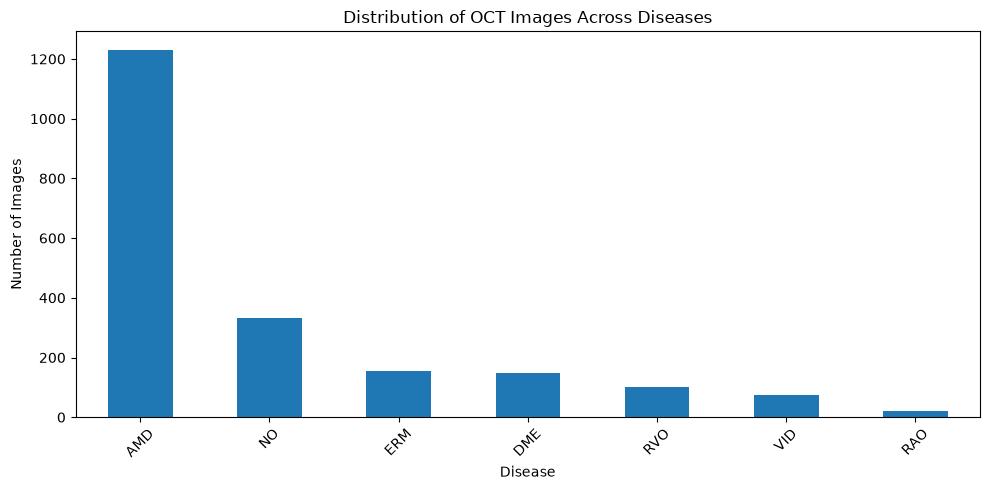

In [10]:
import matplotlib.pyplot as plt

disease_counts = df["disease"].value_counts()

plt.figure(figsize=(10, 5))
disease_counts.plot(kind="bar")

plt.title("Distribution of OCT Images Across Diseases")
plt.xlabel("Disease")
plt.ylabel("Number of Images")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()